# CS 521 HW2, Problem 4
NetID: ws39

I kept the starter's normalization and 784 → 200 → 10 network with one ReLU.
I removed Softmax so CrossEntropyLoss takes logits, and trained for 15 epochs.
This changes the training loss; for fixed logits, the predicted class is unchanged.

Run the cells in order with PyTorch, torchvision, NumPy, and Matplotlib installed.
MNIST downloads automatically. Weights and results are saved in `results/`.
I used CPU, seed 42, and two threads.

Sources: [starter notebook](https://github.com/nalinwadhwa02/CCS521FA26HW/blob/main/hw2/q4/mnist_interval_analysis.ipynb),
[CrossEntropyLoss documentation](https://docs.pytorch.org/docs/2.12/generated/torch.nn.CrossEntropyLoss.html).

In [1]:
import copy
import itertools
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import datasets
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display, Markdown

SEED = 42
BATCH_SIZE = 64
EPOCHS = 15
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
device = torch.device("cpu")
data_dir = Path(os.environ.get("MNIST_DATA_DIR", "mnist_data"))
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)
print(f"PyTorch {torch.__version__}, torchvision {torchvision.__version__}")
print(f"Device: {device}; seed: {SEED}; epochs: {EPOCHS}")

Matplotlib is building the font cache; this may take a moment.


PyTorch 2.12.1, torchvision 0.27.1
Device: cpu; seed: 42; epochs: 15


## Data and model

In [2]:
train_data = datasets.MNIST(data_dir, train=True, download=True)
test_data = datasets.MNIST(data_dir, train=False, download=True)
# Scale to [0, 1], as ToTensor does.
train_x = train_data.data.unsqueeze(1).float() / 255
test_x = test_data.data.unsqueeze(1).float() / 255
train_y, test_y = train_data.targets, test_data.targets
train_loader = DataLoader(TensorDataset(train_x, train_y), batch_size=BATCH_SIZE,
                          shuffle=True, generator=torch.Generator().manual_seed(SEED))
test_loader = DataLoader(TensorDataset(test_x, test_y), batch_size=256, shuffle=False)


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc = nn.Linear(784, 200)
        self.fc2 = nn.Linear(200, 10)

    def forward(self, x):
        x = (x.flatten(1) - 0.1307) / 0.3081
        return self.fc2(F.relu(self.fc(x)))


model = Net().to(device)
print(model)
print(f"Training images: {len(train_y)}; test images: {len(test_y)}")

Net(
  (fc): Linear(in_features=784, out_features=200, bias=True)
  (fc2): Linear(in_features=200, out_features=10, bias=True)
)
Training images: 60000; test images: 10000


## Train for 15 epochs

In [3]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
history = []
training_start = time.perf_counter()
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
    mean_loss = total_loss / len(train_y)
    history.append({"epoch": epoch + 1, "loss": mean_loss})
    print(f"Epoch {epoch + 1:2d}/{EPOCHS}: loss = {mean_loss:.4f}")
    (output_dir / "training_history.json").write_text(json.dumps(history, indent=2))

training_seconds = time.perf_counter() - training_start
model.eval()
with torch.no_grad():
    predictions = torch.cat([model(x.to(device)).argmax(1).cpu() for x, _ in test_loader])
clean_correct = predictions.eq(test_y)
clean_count = int(clean_correct.sum())
clean_accuracy = 100 * clean_count / len(test_y)
torch.save(model.state_dict(), output_dir / "mnist_15epochs.pt")
print(f"Clean test accuracy: {clean_count}/{len(test_y)} = {clean_accuracy:.2f}%")
print(f"Training time: {training_seconds:.1f} s")

Epoch  1/15: loss = 0.5936


Epoch  2/15: loss = 0.2977


Epoch  3/15: loss = 0.2479


Epoch  4/15: loss = 0.2148


Epoch  5/15: loss = 0.1898


...

Epoch 11/15: loss = 0.1124


Epoch 12/15: loss = 0.1052


Epoch 13/15: loss = 0.0988


Epoch 14/15: loss = 0.0931


Epoch 15/15: loss = 0.0880
Clean test accuracy: 9718/10000 = 97.18%
Training time: 5.8 s


## Interval propagation

Start with $l=\max(0,x-\epsilon)$ and $u=\min(1,x+\epsilon)$, then normalize
both endpoints. For a linear layer $Wh+b$, split the weights into
$W^+=\max(W,0)$ and $W^-=\min(W,0)$:
$$l'=W^+l+W^-u+b,\qquad u'=W^+u+W^-l+b.$$
For ReLU, apply $\max(0,\cdot)$ to each endpoint.

I combine the last linear layer with the nine output differences $f_y-f_j$,
$j\ne y$. Each difference has weight $W_y-W_j$ and bias $b_y-b_j$.
This keeps cancellations that separate logit intervals would lose.

An image passes if all nine lower bounds are nonnegative. I use float64
and divide the number that pass by all 10,000 test images.

In [4]:
def affine_bounds(lower, upper, weight, bias):
    positive = weight.clamp(min=0)
    negative = weight.clamp(max=0)
    out_lower = F.linear(lower, positive, bias) + F.linear(upper, negative)
    out_upper = F.linear(upper, positive, bias) + F.linear(lower, negative)
    return out_lower, out_upper


@torch.no_grad()
def margin_bounds(net, images, labels, epsilon):
    x = images.flatten(1).to(dtype=net.fc.weight.dtype, device=net.fc.weight.device)
    labels = labels.to(x.device)
    lower = ((x - epsilon).clamp(0, 1) - 0.1307) / 0.3081
    upper = ((x + epsilon).clamp(0, 1) - 0.1307) / 0.3081
    lower, upper = affine_bounds(lower, upper, net.fc.weight, net.fc.bias)
    lower, upper = lower.relu(), upper.relu()

    classes = torch.arange(10, device=x.device).expand(len(x), 10)
    others = classes[classes != labels[:, None]].reshape(len(x), 9)
    weight = net.fc2.weight[labels, None, :] - net.fc2.weight[others]
    bias = net.fc2.bias[labels, None] - net.fc2.bias[others]
    positive, negative = weight.clamp(min=0), weight.clamp(max=0)
    margin_lower = (positive * lower[:, None, :] + negative * upper[:, None, :]).sum(2) + bias
    margin_upper = (positive * upper[:, None, :] + negative * lower[:, None, :]).sum(2) + bias
    return margin_lower, margin_upper


verification_model = copy.deepcopy(model).cpu().double().eval()

## Checks

In [5]:
# Check the affine bounds against all corners of a small box.
lo = torch.tensor([[-1., 0., 2.]], dtype=torch.float64)
hi = torch.tensor([[2., 3., 4.]], dtype=torch.float64)
weight = torch.tensor([[2., -3., 1.], [-1., 0., -2.]], dtype=torch.float64)
bias = torch.tensor([0.5, -0.5], dtype=torch.float64)
corners = torch.tensor(list(itertools.product(*zip(lo[0].tolist(), hi[0].tolist()))), dtype=torch.float64)
values = F.linear(corners, weight, bias)
bound_lo, bound_hi = affine_bounds(lo, hi, weight, bias)
torch.testing.assert_close(bound_lo[0], values.amin(0))
torch.testing.assert_close(bound_hi[0], values.amax(0))

# Zero-radius bounds should equal the exact margins.
with torch.no_grad():
    point_logits = verification_model(test_x.double())
    exact_margins = point_logits.gather(1, test_y[:, None]) - point_logits
    mask = torch.arange(10)[None, :] != test_y[:, None]
    exact_margins = exact_margins[mask].reshape(-1, 9)
zero_lower, zero_upper = [], []
for images, labels in test_loader:
    lower, upper = margin_bounds(verification_model, images, labels, 0)
    zero_lower.append(lower)
    zero_upper.append(upper)
torch.testing.assert_close(torch.cat(zero_lower), exact_margins, atol=1e-10, rtol=1e-10)
torch.testing.assert_close(torch.cat(zero_upper), exact_margins, atol=1e-10, rtol=1e-10)
assert torch.equal(point_logits.argmax(1), predictions)
assert torch.equal((torch.cat(zero_lower) >= 0).all(1), clean_correct)

# Check that sampled margins stay inside the bounds.
sample_generator = torch.Generator().manual_seed(123)
images, labels = test_x[:16].double(), test_y[:16]
for epsilon in (0.01, 0.05, 0.10):
    lower, upper = margin_bounds(verification_model, images, labels, epsilon)
    for _ in range(20):
        noise = (2 * torch.rand(images.shape, generator=sample_generator, dtype=torch.float64) - 1) * epsilon
        with torch.no_grad():
            logits = verification_model((images + noise).clamp(0, 1))
        margins = logits.gather(1, labels[:, None]) - logits
        margins = margins[torch.arange(10)[None, :] != labels[:, None]].reshape(-1, 9)
        assert (margins >= lower - 1e-10).all() and (margins <= upper + 1e-10).all()
print("Passed: affine corners, zero-radius margins on all 10,000 images, and 960 perturbed inputs.")

Passed: affine corners, zero-radius margins on all 10,000 images, and 960 perturbed inputs.


## Results on all 10,000 test images

In [6]:
epsilons = [i / 100 for i in range(1, 11)]
results = []
certificates = []
worst_margins = []
previous_lower = None
print("epsilon  verified / total  verified accuracy  seconds")
for epsilon in epsilons:
    start = time.perf_counter()
    all_lower = []
    for images, labels in test_loader:
        lower, _ = margin_bounds(verification_model, images, labels, epsilon)
        all_lower.append(lower)
    all_lower = torch.cat(all_lower)
    assert torch.isfinite(all_lower).all()
    if previous_lower is not None:
        assert (all_lower <= previous_lower + 1e-10).all()
    certified = (all_lower >= 0).all(1)
    assert not (certified & ~clean_correct).any()
    if certificates:
        assert not (certified & ~certificates[-1]).any()
    count = int(certified.sum())
    seconds = time.perf_counter() - start
    results.append({"epsilon": epsilon, "verified_count": count, "total": len(test_y),
                    "verified_accuracy": 100 * count / len(test_y), "seconds": seconds})
    certificates.append(certified)
    worst_margins.append(all_lower.amin(1))
    previous_lower = all_lower
    print(f"{epsilon:.2f}     {count:5d} / {len(test_y)}       {100 * count / len(test_y):6.2f}%       {seconds:.2f}")

summary = {"seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE,
           "learning_rate": 0.001, "momentum": 0.9, "device": str(device),
           "torch_version": torch.__version__, "torchvision_version": torchvision.__version__,
           "architecture": [784, 200, 10], "normalization": [0.1307, 0.3081],
           "training_seconds": training_seconds, "clean_count": clean_count,
           "test_size": len(test_y), "clean_accuracy": clean_accuracy, "results": results}
(output_dir / "results.json").write_text(json.dumps(summary, indent=2))
np.savez(output_dir / "certificates.npz", epsilons=epsilons,
         certified=torch.stack(certificates).numpy(),
         worst_margin=torch.stack(worst_margins).numpy(), predictions=predictions.numpy(), labels=test_y.numpy())
print("Passed: certified images are clean-correct, and certification is monotone in epsilon.")

epsilon  verified / total  verified accuracy  seconds


0.01      6234 / 10000        62.34%       0.21


0.02       831 / 10000         8.31%       0.23


0.03        72 / 10000         0.72%       0.22


0.04         4 / 10000         0.04%       0.22


...

0.06         0 / 10000         0.00%       0.21


0.07         0 / 10000         0.00%       0.20


0.08         0 / 10000         0.00%       0.20


0.09         0 / 10000         0.00%       0.24


0.10         0 / 10000         0.00%       0.24
Passed: certified images are clean-correct, and certification is monotone in epsilon.


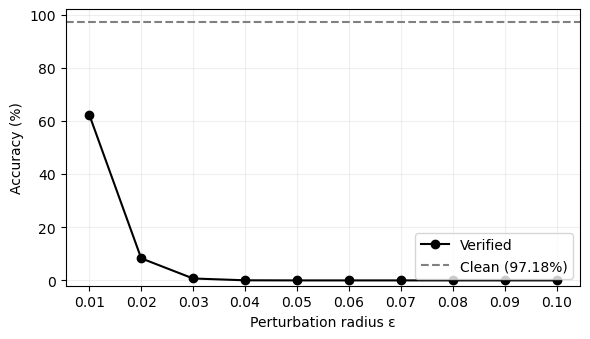

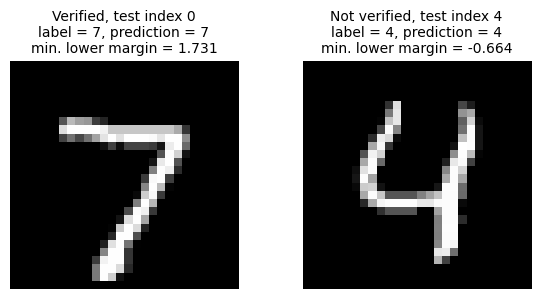

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(epsilons, [row["verified_accuracy"] for row in results], "o-", color="black", label="Verified")
ax.axhline(clean_accuracy, color="gray", linestyle="--", label=f"Clean ({clean_accuracy:.2f}%)")
ax.set(xlabel="Perturbation radius ε", ylabel="Accuracy (%)", ylim=(-2, 102))
ax.set_xticks(epsilons)
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(output_dir / "verified_accuracy.png", dpi=200)
plt.show()

# One passing and one failing example at epsilon = 0.01; both are clean-correct.
groups = [certificates[0], clean_correct & ~certificates[0]]
names = ["Verified", "Not verified"]
examples = [(name, int(torch.where(group)[0][0])) for name, group in zip(names, groups) if group.any()]
fig, axes = plt.subplots(1, len(examples), figsize=(3 * len(examples), 3), squeeze=False)
for ax, (name, idx) in zip(axes[0], examples):
    ax.imshow(test_x[idx, 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{name}, test index {idx}\nlabel = {int(test_y[idx])}, prediction = {int(predictions[idx])}\nmin. lower margin = {worst_margins[0][idx]:.3f}", fontsize=10)
    ax.axis("off")
fig.tight_layout()
fig.savefig(output_dir / "examples.png", dpi=200)
plt.show()

In [8]:
first, last = results[0], results[-1]
zeros = [row["epsilon"] for row in results if row["verified_count"] == 0]
text = (f"The clean accuracy is **{clean_accuracy:.2f}%** ({clean_count}/10,000). "
        f"Interval analysis verifies **{first['verified_accuracy']:.2f}%** at ε = 0.01 "
        f"and **{last['verified_accuracy']:.2f}%** at ε = 0.10. ")
if zeros:
    text += f"The first tested radius with no verified images is ε = {zeros[0]:.2f}. "
text += ("The bounds get wider as ε grows. Interval analysis loses correlations "
         "between hidden neurons, and the model was trained for clean accuracy, not robustness. "
         "Failing verification does not mean an adversarial example exists. "
         "Both example images are classified correctly, but only one passes at ε = 0.01.")
display(Markdown(text))

The clean accuracy is **97.18%** (9718/10,000). Interval analysis verifies **62.34%** at ε = 0.01 and **0.00%** at ε = 0.10. The first tested radius with no verified images is ε = 0.05. The bounds get wider as ε grows. Interval analysis loses correlations between hidden neurons, and the model was trained for clean accuracy, not robustness. Failing verification does not mean an adversarial example exists. Both example images are classified correctly, but only one passes at ε = 0.01.